# FXS / 03b — EURUSD-02 + USDJPY-01 + USDJPY-02 as one compounding portfolio, 2021 → 2026, at prop-firm costs

Question (Iván, 2026-11-10): one account trading the three structures together, position size growing with equity, from 2021 to November 2026, at **$3 per lot round trip** and a **spread 10% tighter than Dukascopy's**.

| Structure | Rule (every trading day, news days included) |
|---|---|
| EURUSD-02 | sell 04:00 → buy 08:00 New York |
| USDJPY-01 | sell 09:55 → buy 10:55 Tokyo |
| USDJPY-02 | buy 09:25 → sell 09:55 Tokyo |

**Fills:** at the quoted Dukascopy bid/ask with the spread scaled to 90% around the mid, plus $3 per 100,000-unit lot. **Sizing:** each day every structure trades `floor(equity × L / 1,000) × 1,000` units (micro lots), so size follows equity. Results in pips and USD.

**Read with care.** This is a descriptive backtest, not a test:
- The three structures were picked using 2021–2025 results (hindsight).
- 2026 has already been looked at once (FXS 05/06): there USDJPY-01 `FAILS` and USDJPY-02 is `INCONCLUSIVE`.
- The 10% tighter spread is an assumption; your real fills at these minutes are not measured yet.

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

E0 = 6_000.0                         # starting equity, USD
LEVERAGES = [1, 2, 3, 5, 10]         # notional per structure as a multiple of current equity
COMMISSION_PER_LOT = 4.0           # USD per 100,000 units, round trip
SPREAD_FACTOR = 0.0                # 10% tighter than Dukascopy
IDS = ["EURUSD-02", "USDJPY-01", "USDJPY-02"]
FROZEN = {"EURUSD-02": ("NY", 660, 900, -1), "USDJPY-01": ("UTC", 55, 115, -1), "USDJPY-02": ("UTC", 25, 55, 1)}
END_2026 = dt.date(2026, 11, 6)

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs03b_")
    os.environ.pop("DUKASCOPY_DIR", None)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
BRANCH = Path.cwd().parent
OUT = Path.cwd() / ("03b_synthetic" if SYNTHETIC else "03b"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40)

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(("EURUSD", "USDJPY")):
        F.write_synthetic_candles(base, p, dt.date(2020, 12, 28), END_2026, seed=7 + i, drift_bps=-3.0 if p == "EURUSD" else 0.0,
                                  drift_ny=(4, 8), price=150.0 if p.endswith("JPY") else 1.10)
    cand = pd.DataFrame([{"id": k, "pair": k[:6], "clock": c, "start": s, "end": e, "direction": d} for k, (c, s, e, d) in FROZEN.items()])
else:
    cand = F.load_frozen_candidates(BRANCH).query("id in @IDS").reset_index(drop=True)
for _, r in cand.iterrows():
    assert (r["clock"], int(r["start"]), int(r["end"]), int(r["direction"])) == FROZEN[r["id"]], f"{r['id']} is not the frozen rule"
PAIR_OF = cand.set_index("id")["pair"]
comm = pd.Series({i: F.commission_bps_per_lot(PAIR_OF[i], COMMISSION_PER_LOT) for i in IDS})

## 1. Daily results per structure, 2021-01 → 2026-11

In [3]:
parts = []
for start, end, stage in ((dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"), (dt.date(2026, 1, 1), END_2026, "holdout")):
    for p in sorted(set(PAIR_OF)):
        cov = F.file_coverage(p, start, end)
        assert cov["share"] >= cfg.min_file_share, f"{p} {start.year}-{end.year}: only {cov['share']:.1%} of day files"
    parts.append(F.structure_detail(cand, start, end, stage, cfg, with_price=True, spread_factor=SPREAD_FACTOR))
G = pd.concat([x[0] for x in parts]).sort_index().fillna(0.0)[IDS]
M = pd.concat([x[1] for x in parts]).sort_index().fillna(0.0)[IDS]
P = pd.concat([x[2] for x in parts]).sort_index().ffill().bfill()[IDS]
N = G - comm                                                     # net, fraction-of-price units (bps)
traded = G != 0
pips = pd.DataFrame({i: F.bps_to_pips(N[i], P[i], PAIR_OF[i]) for i in IDS}, index=N.index).where(traded)
usd_lot = pd.DataFrame({i: pips[i] * F.usd_per_pip_per_lot(PAIR_OF[i], P[i]) for i in IDS}, index=N.index)
spread_pips = pd.DataFrame({i: F.bps_to_pips(G[i] - pd.concat([y[0] for y in [F.structure_detail(cand, *w, cfg, spread_factor=0.0)
                                                                              for w in ((dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"), (dt.date(2026, 1, 1), END_2026, "holdout"))]]).sort_index()[i],
                                             P[i], PAIR_OF[i]) for i in IDS}, index=N.index).where(traded)
summary_tab = pd.DataFrame({"trades": traded.sum(), "net pips/trade": pips.mean(), "USD per 1-lot trade": usd_lot.mean(),
                            "win rate": (pips > 0).sum() / traded.sum(), "spread paid, pips (round trip)": -spread_pips.mean(),
                            "commission, pips": pd.Series({i: F.bps_to_pips(comm[i], P[i][traded[i]], PAIR_OF[i]).mean() for i in IDS}),
                            "worst open loss, pips": pd.DataFrame({i: F.bps_to_pips(M[i], P[i], PAIR_OF[i]) for i in IDS}).min()})
display(summary_tab.round(2)); summary_tab.to_csv(OUT / "03b_structures.csv")
yearly = pips.groupby(pips.index.year).mean()
yearly["portfolio USD/day, 1 lot each"] = usd_lot.sum(axis=1).groupby(usd_lot.index.year).mean()
display(yearly.round(2)); yearly.to_csv(OUT / "03b_yearly_pips.csv")

,trades,net pips/trade,USD per 1-lot trade,win rate,"spread paid, pips (round trip)","commission, pips","worst open loss, pips"
EURUSD-02,1516,1.65,16.50,0.54,-0.0,0.40,-152.93
USDJPY-01,1516,1.13,7.92,0.53,-0.0,0.56,-246.69
USDJPY-02,1516,1.05,7.89,0.55,-0.0,0.56,-250.78


,EURUSD-02,USDJPY-01,USDJPY-02,"portfolio USD/day, 1 lot each"
2021,2.00,0.64,1.08,35.20
2022,4.50,2.34,2.77,83.62
2023,1.50,0.92,0.60,25.42
2024,0.42,1.34,1.44,22.21
2025,0.46,1.72,0.22,16.60
2026,0.90,-0.43,0.05,6.48


## 2. The compounding account

Each structure gets L × current equity of notional every day; the three are never all open at the same minute (EURUSD-02 is in the European morning, the two USDJPY legs back to back in the Tokyo morning). `worst day` is the worst open loss of any day, all structures at their worst minute, as a share of that morning's equity.

,L each,lots per $10k equity (EURUSD),final_equity,cagr,ann_vol,sharpe,max_drawdown,worst_year,best_year,ruined,worst day,days below start
0,1,0.09,9232.0,7.7%,3.8%,1.904883,-3.7%,1.1%,21.6%,False,-2.1%,9
1,2,0.18,14568.0,16.4%,7.9%,1.911480,-7.9%,2.1%,49.9%,False,-4.2%,9
2,3,0.27,22754.0,25.7%,11.9%,1.914776,-11.8%,3.1%,84.8%,False,-6.3%,9
3,5,0.45,54024.0,45.7%,20.0%,1.920999,-19.3%,4.7%,177.7%,False,-10.5%,9
4,10,0.91,386607.0,104.1%,40.2%,1.921357,-35.9%,6.7%,619.1%,False,-21.1%,9


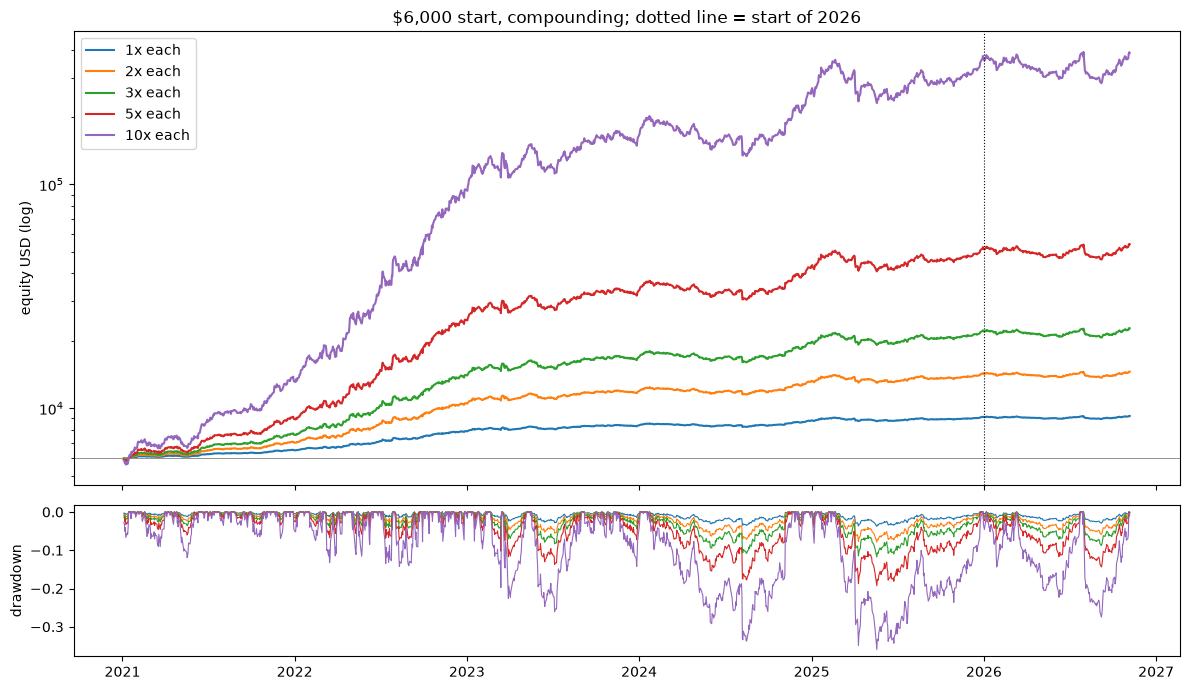

In [4]:
rows, curves = [], {}
for L in LEVERAGES:
    w = pd.Series(float(L), index=IDS)
    acc = F.simulate_account(N, w, E0)
    curves[L] = acc
    prev = acc["equity"].shift(1).fillna(E0).to_numpy()
    units = np.floor(prev[:, None] * L / 1000) * 1000
    worst = (units * (M.to_numpy() - comm.to_numpy())).sum(axis=1) / 1e4 / np.maximum(prev, 1e-9)
    st = F.account_stats(acc, E0)
    rows.append({"L each": L, "lots per $10k equity (EURUSD)": round(L * 10_000 / 100_000 / 1.10, 2), **st,
                 "worst day": float(worst.min()), "days below start": int((acc["equity"] < E0).sum())})
res = pd.DataFrame(rows)
show = res.copy()
for c in ("cagr", "ann_vol", "max_drawdown", "worst_year", "best_year", "worst day"):
    show[c] = (100 * show[c]).round(1).astype(str) + "%"
show["final_equity"] = show["final_equity"].round(0)
display(show); res.to_csv(OUT / "03b_account.csv", index=False)
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for L in LEVERAGES:
    ax[0].plot(curves[L]["equity"], label=f"{L}x each")
    ax[1].plot(curves[L]["drawdown"], lw=0.8)
ax[0].axhline(E0, color="grey", lw=0.6); ax[0].axvline(pd.Timestamp("2026-01-01"), color="black", ls=":", lw=0.8)
ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_ylabel("equity USD (log)"); ax[0].set_title(f"${E0:,.0f} start, compounding; dotted line = start of 2026")
ax[1].set_ylabel("drawdown")
plt.tight_layout(); plt.savefig(OUT / "03b_equity.png", dpi=110); plt.show()

## 3. Year by year (account return, %)

In [5]:
yr = pd.DataFrame({f"{L}x": (lambda e: e.resample("YE").last().pct_change().fillna(e.resample("YE").last().iloc[0] / E0 - 1))(curves[L]["equity"])
                   for L in LEVERAGES})
yr.index = yr.index.year
display((100 * yr).round(1)); yr.to_csv(OUT / "03b_yearly_returns.csv")

,1x,2x,3x,5x,10x
2021,8.2,17.0,26.8,48.9,119.3
2022,21.6,49.9,84.8,177.7,619.1
2023,5.9,12.6,19.4,33.4,69.9
2024,5.4,11.5,17.5,30.2,63.7
2025,3.6,8.0,11.9,19.7,37.7
2026,1.1,2.1,3.1,4.7,6.7


## 4. Where the money came from (2× each)

,USD 2021-2025,USD 2026,USD total
EURUSD-02,3512.0,484.0,3995.0
USDJPY-01,2661.0,-180.0,2480.0
USDJPY-02,2098.0,-5.0,2093.0


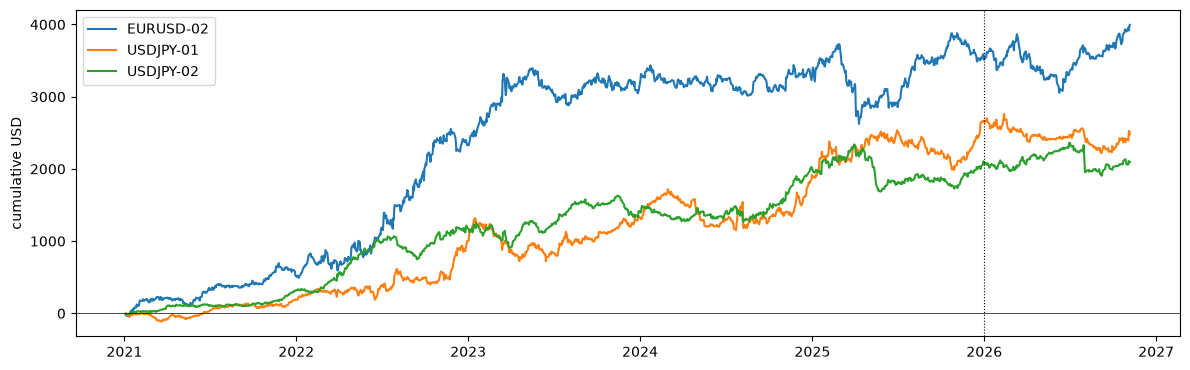

In [6]:
L = 2
prev = curves[L]["equity"].shift(1).fillna(E0).to_numpy()
units = np.floor(prev[:, None] * L / 1000) * 1000
pnl = pd.DataFrame(units * N.to_numpy() / 1e4, index=N.index, columns=IDS)
contrib = pd.DataFrame({"USD 2021-2025": pnl[:"2025"].sum(), "USD 2026": pnl["2026":].sum(), "USD total": pnl.sum()})
display(contrib.round(0))
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(pnl.cumsum()); ax.axhline(0, color="black", lw=0.5); ax.legend(IDS)
ax.axvline(pd.Timestamp("2026-01-01"), color="black", ls=":", lw=0.8); ax.set_ylabel("cumulative USD")
plt.tight_layout(); plt.savefig(OUT / "03b_contribution.png", dpi=110); plt.show()

## 5. Cost sensitivity (2× each)

Same trades, different costs: how much of the result depends on the assumed spread and commission.

In [9]:
sens = []
spread_cost = G - pd.concat([F.structure_detail(cand, *w, cfg, spread_factor=1.0)[0] for w in
                             ((dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"), (dt.date(2026, 1, 1), END_2026, "holdout"))]).sort_index()[IDS]
G_full = G - spread_cost                                      # at 100% of the Dukascopy spread
for sf, Gx in ((0.0, G), (1.0, G_full)):
    for c in (0.0, 4.0, 7.0):
        cm = pd.Series({i: F.commission_bps_per_lot(PAIR_OF[i], c) for i in IDS})
        acc = F.simulate_account(Gx - cm, pd.Series(2.0, index=IDS), E0)
        st = F.account_stats(acc, E0)
        sens.append({"spread": f"{int(sf * 100)}% of Dukascopy", "commission $/lot": c, "final_equity": round(st["final_equity"]),
                     "cagr %": round(100 * st["cagr"], 1), "max drawdown %": round(100 * st["max_drawdown"], 1)})
display(pd.DataFrame(sens)); pd.DataFrame(sens).to_csv(OUT / "03b_cost_sensitivity.csv", index=False)

,spread,commission $/lot,final_equity,cagr %,max drawdown %
0,0% of Dukascopy,0.0,20650,23.6,-7.0
1,0% of Dukascopy,4.0,14568,16.4,-7.9
2,0% of Dukascopy,7.0,11227,11.3,-9.5
3,100% of Dukascopy,0.0,14620,16.5,-8.3
4,100% of Dukascopy,4.0,10294,9.7,-10.5
5,100% of Dukascopy,7.0,8011,5.1,-16.1


In [8]:
summary = {"study": "FXS03b", "descriptive": True, "synthetic": SYNTHETIC, "window": ["2021-01-01", str(END_2026)],
           "structures": IDS, "equity0": E0, "commission_usd_per_lot_rt": COMMISSION_PER_LOT, "spread_factor": SPREAD_FACTOR,
           "per_structure": summary_tab.round(4).reset_index().to_dict(orient="records"), "account": res.to_dict(orient="records"),
           "note": "Hindsight selection; 2026 already seen in FXS 05/06 (USDJPY-01 FAILS, USDJPY-02 INCONCLUSIVE). Not a test."}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\03b\summary.json
